# A4. 사람들은 무엇을 칭찬하고 무엇에 불만인가

**담당:** 이고은 · **데이터:** 2026-11-26 elk ES `reviews` (게임 1,000개, 한국어 리뷰 게임당 최대 약 500건)

## 한 줄 결론
> 불만은 **게임성·재미와 버그**가 가장 크고, 가격 때문인 불만은 8%뿐이다. 그런데 **서버·버그·가격이 주된 불만인 게임은 평가가 더 낮다.** 가격이 내려갔다고 사도 후회 없는 게임은 아니다.

## 가설
1. 불만과 만족의 이유는 몇 가지 유형으로 묶인다.
2. 장르마다 불만의 유형이 다르다.
3. 어떤 불만인지에 따라 게임 평가(긍정률)가 다르다.

## 방법
1. ES에서 게임마다 **칭찬 키워드**(긍정 리뷰에서 부정보다 두드러지게 많이 나온 명사)와 **불만 키워드**(그 반대)를 받는다 (`significant_terms`). 리뷰 원문은 가져오지 않는다.
2. 사전(`analysis/dictionaries/review_types.json`)으로 키워드를 유형에 묶는다.
3. 게임마다 유형 **비중**을 구하고, 전체·장르는 게임당 1표로 평균한다 (리뷰가 많은 게임 하나가 결과를 끌지 않게).

In [1]:
import json, os, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from scipy import stats

# 한글 글꼴: 있는 것 중 첫 번째를 쓴다 (Windows·Mac·Linux 공통)
for f in ("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc", "/usr/share/fonts/opentype/noto/NotoSansCJK-Bold.ttc"):
    if Path(f).exists():
        font_manager.fontManager.addfont(f)
have = {f.name for f in font_manager.fontManager.ttflist}
for name in ("Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP"):
    if name in have:
        plt.rcParams["font.family"] = name
        break
plt.rcParams.update({"axes.unicode_minus": False, "font.size": 12, "axes.edgecolor": "#c9c8c3",
                     "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e"})

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#a3a29d"
INK, MUTED, GRID, BG = "#0b0b0b", "#52514e", "#e8e7e3", "#fcfcfb"
DATA = Path(os.environ.get("GAMENURI_DATA_DIR", "../data"))   # 노트북은 analysis/notebooks 에서 연다


def frame(ax, grid="both"):
    """차트 바탕: 옅은 격자, 위·오른쪽 테두리 제거"""
    ax.set_facecolor(BG)
    ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

sys.path.insert(0, str(Path("..").resolve()))      # analysis/review_types.py 를 불러오기 위해
from collections import defaultdict
from review_types import aggregate, is_ignored, labels, load_dict

## 1. 키워드 데이터와 유형 사전

In [2]:
kw = pd.read_csv(DATA / "a4_keywords.tsv", sep="\t", keep_default_na=False, dtype={"keyword": str})
print(f"키워드 {len(kw):,}줄, 게임 {kw.game_id.nunique()}개")
kw.head()

키워드 65,759줄, 게임 1000개


,game_id,steam_appid,total,positive,negative,side,keyword,doc_count,score
0,1877,1091500,519,484,35,positive,나이트,16,1.1938
1,1877,1091500,519,484,35,positive,최고,16,1.1938
2,1877,1091500,519,484,35,positive,시티,16,1.1938
3,1877,1091500,519,484,35,positive,goat,13,0.9642
4,1877,1091500,519,484,35,positive,엣지,12,0.8883


In [3]:
d = load_dict()
neg_labels, pos_labels = labels(d, "negative"), labels(d, "positive")

# 유형별 예시 키워드 (한국어는 앞부분이 같으면 그 유형)
ex = [(side, v["label"], ", ".join(v.get("ko", [])[:6] + v.get("en", [])[:2]))
      for side in ("negative", "positive") for v in d[side].values()]
pd.DataFrame(ex, columns=["쪽", "유형", "예시 키워드"]).replace({"negative": "불만", "positive": "만족"})

,쪽,유형,예시 키워드
0,불만,가격·과금,"bm, dlc, 가격, 가성비, 강화, 결제, price, expensive"
1,불만,최적화·성능,"그래픽카드, 끊겨, 끊김, 드랍, 렉, 로드, optimization, optimized"
2,불만,서버·운영,"ea, pvp, 개발자, 검열, 계정, 넥슨, server, servers"
3,불만,번역·한글,"번역, 한글, 한국어, 자막, 오역, 더빙, translation, localization"
4,불만,버그·오류,"강제, 낙사, 먹통, 멈춤, 미완성, 발생, bug, bugs"
5,불만,콘텐츠 부족·반복,"노가다, 단순, 단조, 루즈, 무한, 미니게임, content, short"
6,불만,조작·화면,"ui, 마우스, 메뉴, 모션, 버튼, 불편, ui, controls"
7,불만,난이도·밸런스,"qte, 가드, 고정, 난이도, 난잡, 난해, difficulty, balance"
8,불만,스토리·연출,"스토리, 엔딩, 캐릭, 주인공, 대사, 연출, story, ending"
9,불만,게임성·재미,"재미, 전투, 보스, 공격, 이동, 진행, fun, combat"


## 2. 키워드를 유형으로 묶고, 게임별 비중 구하기

In [4]:
MIN_CLASSIFIED = 10    # 분류된 키워드 건수가 이보다 적은 게임은 비중이 흔들려 뺀다
games = pd.read_csv(Path("../game_list/games_1000.csv"), encoding="utf-8-sig").drop_duplicates("game_id").set_index("game_id")

rows = []
for (gid, side), g in kw.groupby(["game_id", "side"]):
    pairs = list(zip(g.keyword.astype(str), g.doc_count.astype(int), strict=True))
    counts, _unknown = aggregate(pairs, d, side)
    total_all = sum(n for w, n in pairs if not is_ignored(w, d))
    rows.append({"game_id": gid, "side": side, "classified": sum(counts.values()), "all": total_all, "counts": counts})
res = pd.DataFrame(rows)


def shares(side, keys):
    """게임 x 유형 비중 (한 게임의 비중 합 = 1)"""
    out = {r.game_id: {k: r.counts.get(k, 0) / r.classified for k in keys}
           for r in res[res.side == side].itertuples() if r.classified >= MIN_CLASSIFIED}
    return pd.DataFrame.from_dict(out, orient="index", columns=keys).fillna(0.0)


info = games[["name_ko", "name", "genres", "positive_pct_ko", "review_count_ko"]]
neg = shares("negative", list(neg_labels)).join(info, how="left")
pos = shares("positive", list(pos_labels)).join(info, how="left")

for side, label in (("negative", "불만"), ("positive", "만족")):
    s = res[res.side == side]
    print(f"{label}: 게임 {len(s)}개 중 {int((s.classified >= MIN_CLASSIFIED).sum())}개 사용, 사전에 걸린 키워드 비율 {s.classified.sum() / s['all'].sum():.0%}")

불만: 게임 963개 중 796개 사용, 사전에 걸린 키워드 비율 64%
만족: 게임 1000개 중 968개 사용, 사전에 걸린 키워드 비율 40%


## 3. 불만과 만족은 무엇 때문인가

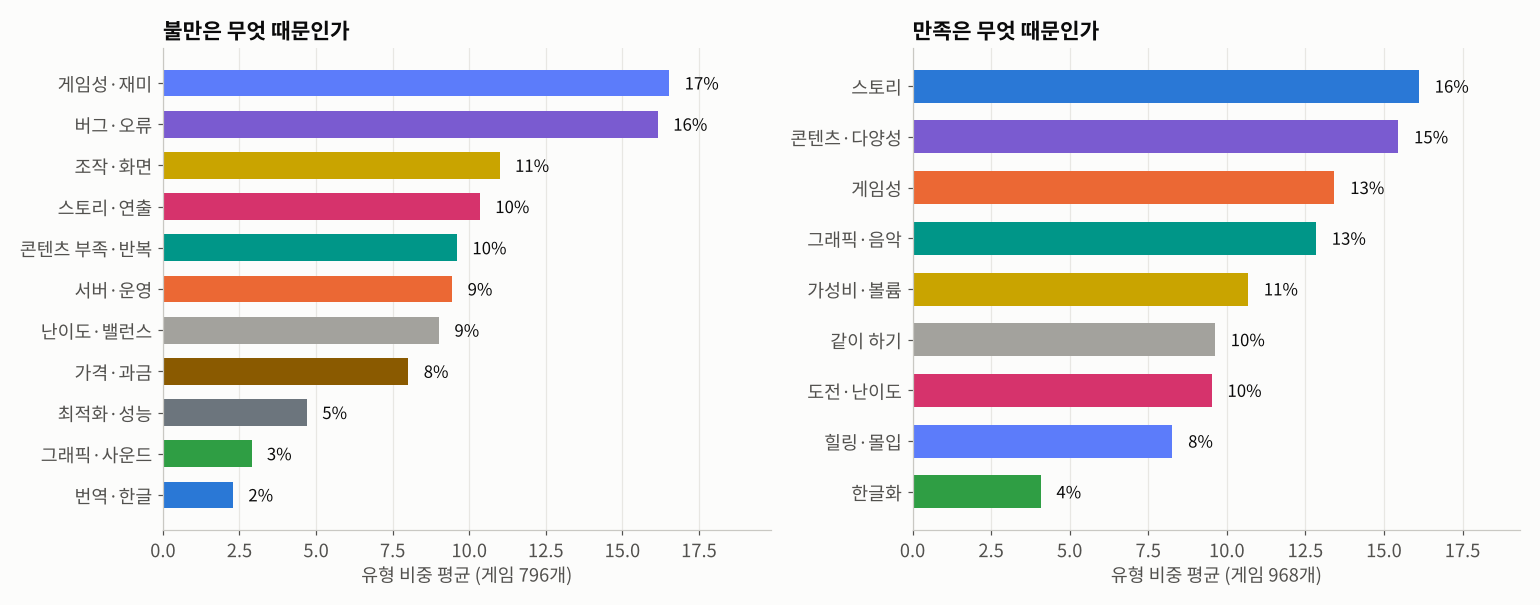

In [5]:
NEG_COLORS = ["#8a5a00", "#6c757d", "#eb6834", "#2a78d6", "#7a5bd0", "#009688", "#c9a400", "#a3a29d", "#d6336c", "#5c7cfa", "#2f9e44"]
POS_COLORS = ["#2a78d6", "#009688", "#eb6834", "#c9a400", "#7a5bd0", "#a3a29d", "#d6336c", "#5c7cfa", "#2f9e44"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), facecolor=BG)
for ax, df, lab, colors, title in ((axes[0], neg, neg_labels, NEG_COLORS, "불만은 무엇 때문인가"),
                                   (axes[1], pos, pos_labels, POS_COLORS, "만족은 무엇 때문인가")):
    m = df[list(lab)].mean().sort_values() * 100
    ax.barh([lab[k] for k in m.index], m.values, color=[colors[list(lab).index(k)] for k in m.index], height=0.65)
    for y, v in enumerate(m.values):
        ax.text(v + 0.5, y, f"{v:.0f}%", va="center", color=INK, fontsize=11)
    ax.set_xlim(0, m.max() * 1.2)
    ax.set_xlabel(f"유형 비중 평균 (게임 {len(df)}개)")
    ax.set_title(title, loc="left", color=INK, fontweight="bold", fontsize=14)
    frame(ax, "x")
plt.tight_layout(); plt.show()

**의미 판단:** 불만은 **게임성·재미(17%)와 버그·오류(16%)**가 가장 크고, 가격·과금은 8%, 번역·한글은 2%로 작다. 만족은 **스토리(16%)와 콘텐츠·다양성(15%)**이 크다. "비싸서"보다 "재미없거나 버그가 많아서" 불만이 더 많다.

## 4. 장르마다 불만과 만족의 유형이 다르다

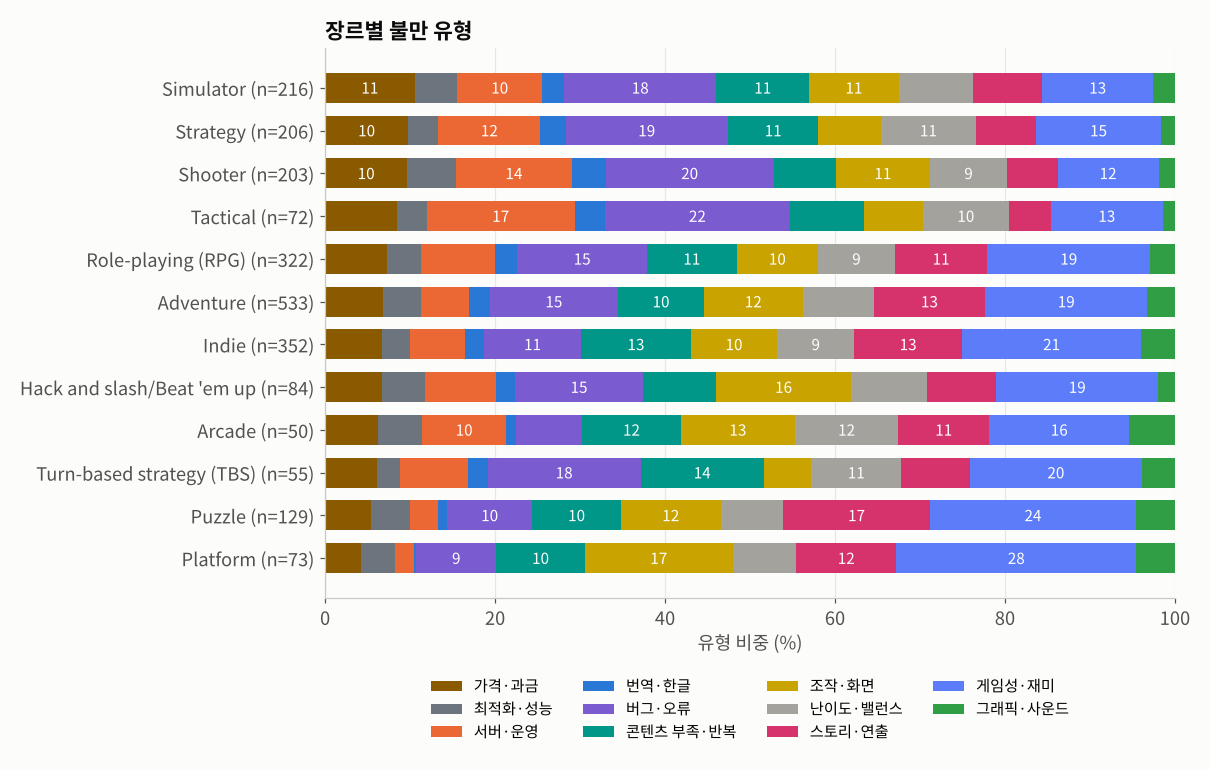

In [6]:
MIN_GENRE, TOP_GENRES = 20, 12     # 장르에 게임이 20개 이상인 상위 12개 장르만 비교


def genre_table(df, keys):
    rows = [{"genre": g, **{k: r[k] for k in keys}} for _, r in df.iterrows() for g in str(r.genres).split("|") if g and g != "nan"]
    t = pd.DataFrame(rows)
    n = t.groupby("genre").size()
    t = t.groupby("genre").mean(numeric_only=True)
    t["n"] = n
    return t[t.n >= MIN_GENRE].sort_values("n", ascending=False).head(TOP_GENRES)


def stacked(ax, t, lab, colors, title):
    keys = list(lab)
    order = t.sort_values(keys[0], ascending=True)
    left = np.zeros(len(order))
    for i, k in enumerate(keys):
        v = order[k].values * 100
        ax.barh(order.index, v, left=left, color=colors[i % len(colors)], label=lab[k], height=0.7)
        for j, (x, w) in enumerate(zip(left, v, strict=True)):
            if w >= 9:
                ax.text(x + w / 2, j, f"{w:.0f}", ha="center", va="center", color="white", fontsize=10)
        left += v
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels([f"{g} (n={int(order.n[g])})" for g in order.index])
    ax.set_xlim(0, 100)
    ax.set_xlabel("유형 비중 (%)")
    ax.set_title(title, loc="left", color=INK, fontweight="bold", fontsize=14)
    ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False, fontsize=10)
    frame(ax, "x")


gn, gp = genre_table(neg, list(neg_labels)), genre_table(pos, list(pos_labels))
fig, ax = plt.subplots(figsize=(11, 7), facecolor=BG)
stacked(ax, gn, neg_labels, NEG_COLORS, "장르별 불만 유형")
plt.tight_layout(); plt.show()

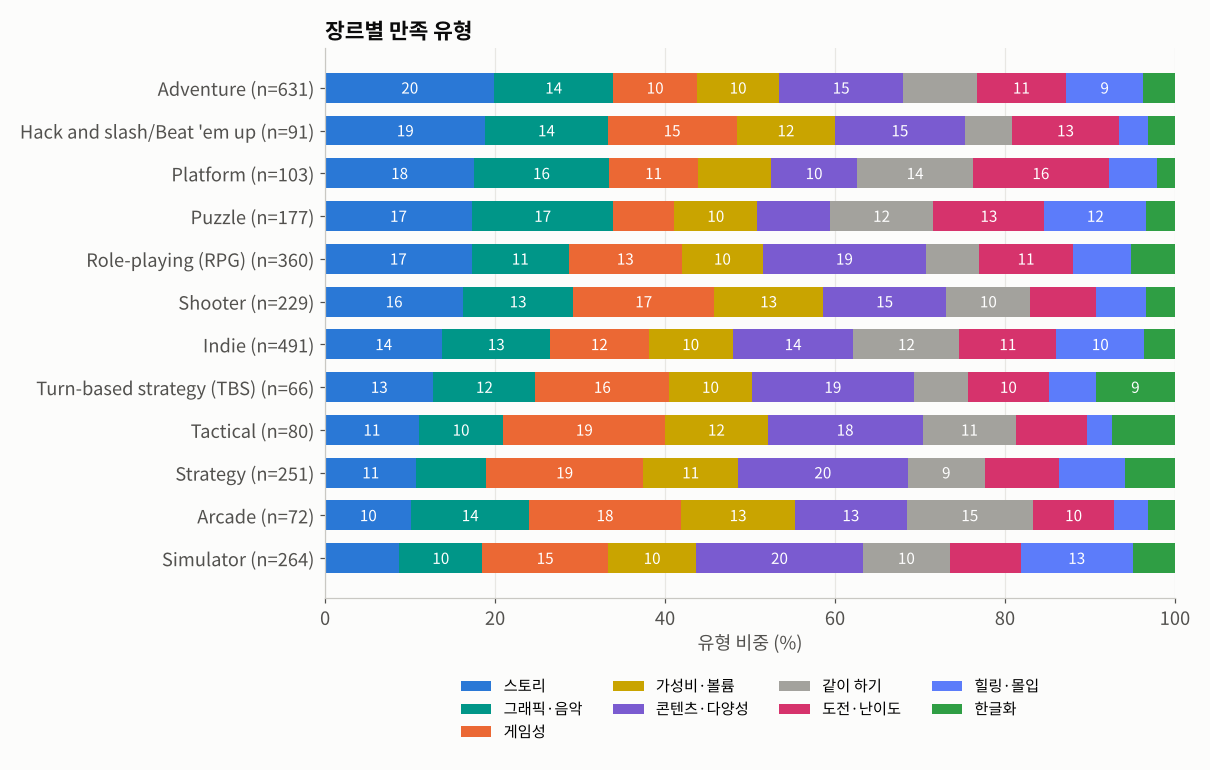

In [7]:
fig, ax = plt.subplots(figsize=(11, 7), facecolor=BG)
stacked(ax, gp, pos_labels, POS_COLORS, "장르별 만족 유형")
plt.tight_layout(); plt.show()

**의미 판단:** 슈터·택티컬·전략·시뮬레이터는 **버그 불만이 18~22%**로 가장 크고, 슈터·택티컬은 서버·운영 불만도 14~17%다. 퍼즐·플랫폼·인디는 **게임성·재미 불만이 21~28%**로 압도적이다. 만족은 전략·시뮬레이터·RPG가 콘텐츠·다양성, 어드벤처·퍼즐·플랫폼이 스토리, 슈터·택티컬·아케이드가 게임성 쪽이다. 어느 장르를 만들든 "그 장르가 흔히 듣는 불만"이 정해져 있다.

## 5. 어떤 불만이냐에 따라 평가가 다르다

서버·버그·가격이 주된 불만: 평균 75% (n=276) / 그 밖: 평균 83% (n=520), 맨-휘트니 p = 1.1e-19


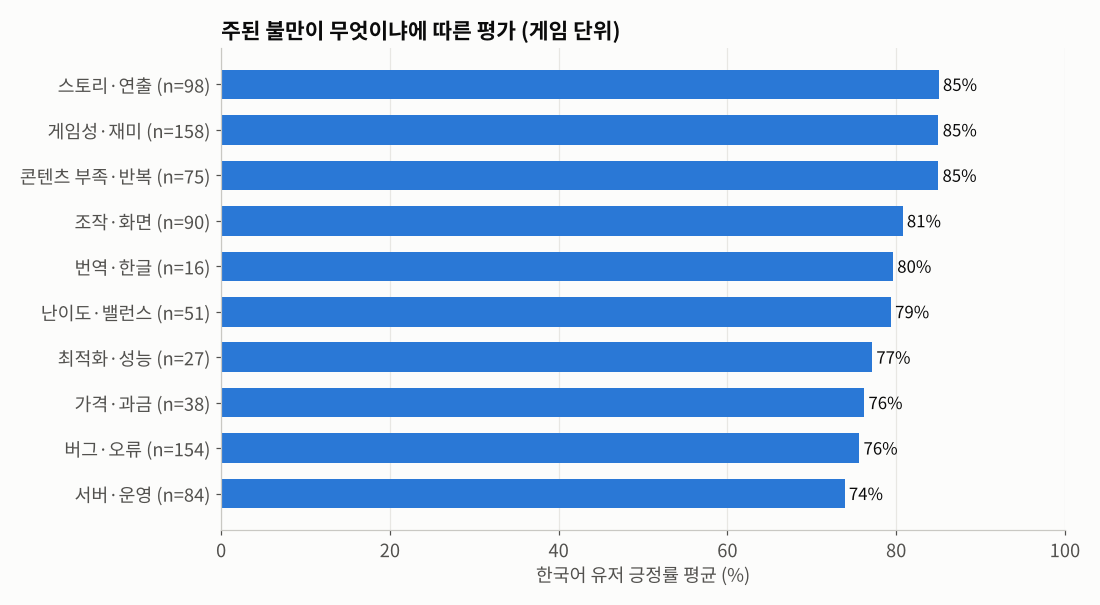

In [8]:
neg["dominant"] = neg[list(neg_labels)].idxmax(axis=1)       # 게임마다 비중이 가장 큰 불만 유형
dom = (neg.dropna(subset=["positive_pct_ko"]).groupby("dominant").positive_pct_ko.agg(["mean", "count"]))
dom = dom[dom["count"] >= 10].sort_values("mean")

fig, ax = plt.subplots(figsize=(10, 5.5), facecolor=BG)
ax.barh([f"{neg_labels[k]} (n={int(dom['count'][k])})" for k in dom.index], dom["mean"].values, color=BLUE, height=0.65)
for y, v in enumerate(dom["mean"].values):
    ax.text(v + 0.5, y, f"{v:.0f}%", va="center", color=INK, fontsize=11)
ax.set_xlim(0, 100)
ax.set_xlabel("한국어 유저 긍정률 평균 (%)")
ax.set_title("주된 불만이 무엇이냐에 따른 평가 (게임 단위)", loc="left", color=INK, fontweight="bold", fontsize=14)
frame(ax, "x")
plt.tight_layout(); plt.show()

# 통계 검정: 서버·버그·가격이 주된 불만인 게임 vs 그 밖의 게임 (맨-휘트니 U 검정)
risky = neg.dominant.isin(["server", "bug", "price"])
x1 = neg[risky].positive_pct_ko.dropna()
x2 = neg[~risky].positive_pct_ko.dropna()
u = stats.mannwhitneyu(x1, x2, alternative="less")
print(f"서버·버그·가격이 주된 불만: 평균 {x1.mean():.0f}% (n={len(x1)}) / 그 밖: 평균 {x2.mean():.0f}% (n={len(x2)}), 맨-휘트니 p = {u.pvalue:.1e}")

**의미 판단:** 주된 불만이 서버·운영, 버그, 가격이면 긍정률이 74~76%로 낮고, 스토리·콘텐츠·게임성이 주된 불만이면 85%다. 서버·버그·가격 전체와 그 밖의 게임을 비교하면 평균 75% 대 83%이고 차이는 통계적으로 유의하다(맨-휘트니 p < 0.001). 같은 "불만"이어도 서버·버그·가격 때문이면 평가가 더 깎인다. (같이 나타나는 현상이지 원인은 아니다.)

## 6. 서비스에 쓰는 법: 구매 조건 문구

In [9]:
def game_name(row):
    ko = row["name_ko"]
    return ko if isinstance(ko, str) and ko.strip() else str(row["name"])


price_ok = neg[neg.positive_pct_ko >= 80].sort_values("price", ascending=False).head(10)   # 가격 불만이 크지만 평가는 좋은 게임
bug_risk = neg[neg.positive_pct_ko < 70].sort_values("bug", ascending=False).head(10)      # 버그 불만이 큰 저평가 게임

out = pd.DataFrame({
    "할인 때 사면 만족하는 게임": [game_name(r) for _, r in price_ok.iterrows()],
    "패치 상태를 보고 사야 하는 게임": [game_name(r) for _, r in bug_risk.iterrows()],
})
out

,할인 때 사면 만족하는 게임,패치 상태를 보고 사야 하는 게임
0,언패킹,마피아 II 데피니티브 에디션
1,킬링 플로어,The Wild Eight
2,하츠 오브 아이언 4,스나이퍼 고스트 워리어 컨트랙트
3,블루 아카이브,Ixion
4,Tangle Tower,바이오쇼크 2 리마스터
5,스텔라리스,폴리스 시뮬레이터: 패트롤 오피서
6,시티즈: 스카이 라인,배틀필드 3
7,Donut County,휴먼카인드
8,씨 오브 시브즈,마피아 III
9,토탈워: 워해머 2,Stranded Deep


## 인사이트와 활용

| 인사이트 | 서비스·수익에 쓰는 법 |
|---|---|
| 가격 불만은 8%뿐, 게임성·버그가 더 큼 | "싸다"만으로는 만족을 보장하지 못한다. 가격과 함께 불만 유형을 보여 준다 |
| 서버·버그·가격이 주된 불만이면 긍정률 평균 75% (그 외 83%) | 목표가 알림에 **불만 유형 문구**를 붙인다. 예) "지금 최저가예요. 다만 서버 불만이 많아요" |
| 가격 불만이 크지만 평가가 좋은 게임이 있음 | "할인할 때 사면 만족하는 게임" 추천 |
| 장르마다 흔한 불만이 정해져 있음 | 메일에 함께 싣는 **제휴 추천** 게임은 불만 유형이 적은 게임을 우선한다 |

**수익 연결: "사도 후회 없는 때" 알림.** 가격과 품질(불만 유형)이 모두 괜찮을 때 알려 주면 유저 신뢰가 올라 구매 링크 **제휴 수수료**가 늘고, 같은 메일에 제휴사가 비용을 낸 추천 게임도 함께 싣는다. 알림은 이미 구현된 메일 알림을 그대로 쓴다.

## 한계
- 사전에 걸린 키워드 비율은 불만 64%, 만족 40%다. 나머지는 게임 이름·고유명사·장르 이름처럼 유형이 될 수 없는 말이 많다.
- 리뷰는 게임당 최대 약 500건(최근·유용 순 표본)이라 전체 리뷰와 다를 수 있다.
- 유형 비중은 키워드 건수 기반이고 인과가 아니라 같이 나타나는 현상이다. 기간별로 불만이 줄었는지는 아직 보지 못했다(향후 확장). 매출 금액은 추정하지 않는다.